# Waste Management Expenditure, Nonthaburi Province

**Data:** `data/raw/pay_garbage.csv` — expenditure per local government per year (Buddhist Era 2563–2567 = 2020–2024) in 6 categories: equipment purchases, fuel, system maintenance, worker wages, collection & transport, disposal (unit: baht)

**Steps:** load → convert numbers (remove `,`) and fill gaps with 0 → save `clean_pay.csv` → analyze with charts: cost structure, by district, highest-spending local governments, and **cost per tonne of waste**

# ค่าใช้จ่ายในการบริหารจัดการขยะ จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/pay_garbage.csv` — ค่าใช้จ่ายราย อปท. รายปี (พ.ศ. 2563–2567) แบ่งเป็น 6 หมวด: ค่าจัดซื้อครุภัณฑ์, ค่าน้ำมัน, ค่าบำรุงรักษาระบบ, ค่าจ้างคนงาน, ค่าเก็บขน, ค่ากำจัด (หน่วย: บาท)

**ขั้นตอน:** โหลด → แปลงตัวเลข (ลบ `,`) และเติมค่าว่างเป็น 0 → บันทึก `clean_pay.csv` → วิเคราะห์ด้วยกราฟ: โครงสร้างค่าใช้จ่าย, รายอำเภอ, อปท. ที่ใช้จ่ายสูง และ **ต้นทุนต่อตันขยะ**

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/pay_garbage.csv` — money values contain `,` separators and decimals

**โหลดข้อมูลดิบ** จาก `../data/raw/pay_garbage.csv` — ตัวเลขเงินมีเครื่องหมาย `,` และทศนิยม

In [2]:
df = pd.read_csv('../data/raw/pay_garbage.csv')
df

,ปี,จังหวัด,อำเภอ,อปท,ค่าจัดซื้อครุภัณฑ์,ค่าน้ำมัน,ค่าบำรุงรักษาระบบ,ค่าจ้างคนงาน,ค่าเก็บขน,ค่ากำจัด
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,"480,000","13,224,077.55","14,992,777.50","53,846,100",0,0
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,0,"3,817,505.20","3,616,434.50","11,121,033",0,0
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0,"1,630,042.41","1,362,725.26","2,949,720",0,0
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,"2,400,000","2,416,373.20","2,416,380.65","4,032,000",0,0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,"500,000","2,370,540.70","1,000,000.00","6,234,000",0,0
...,...,...,...,...,...,...,...,...,...,...
145,2567,นนทบุรี,ไทรน้อย,อบต.ราษฎร์นิยม,NaN,NaN,NaN,NaN,NaN,NaN
146,2567,นนทบุรี,บางบัวทอง,อบต.ละหาร,NaN,NaN,NaN,NaN,NaN,NaN
147,2567,นนทบุรี,บางบัวทอง,อบต.ลำโพ,0,"1,000,000","600,000","2,208,000",0,0
148,2567,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,NaN,NaN,NaN,NaN,NaN,NaN


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ปี                  150 non-null    int64 
 1   จังหวัด             150 non-null    object
 2   อำเภอ               150 non-null    object
 3   อปท                 150 non-null    object
 4   ค่าจัดซื้อครุภัณฑ์  100 non-null    object
 5   ค่าน้ำมัน           100 non-null    object
 6   ค่าบำรุงรักษาระบบ   100 non-null    object
 7   ค่าจ้างคนงาน        100 non-null    object
 8   ค่าเก็บขน           100 non-null    object
 9   ค่ากำจัด            100 non-null    object
dtypes: int64(1), object(9)
memory usage: 11.8+ KB


**Look at the first 5 rows** with `head()` to confirm the data is in the right format

**ดูตัวอย่าง 5 แถวแรก** ด้วย `head()` เพื่อยืนยันว่าข้อมูลอยู่ในรูปแบบที่ถูกต้อง

In [4]:
df.head()

,ปี,จังหวัด,อำเภอ,อปท,ค่าจัดซื้อครุภัณฑ์,ค่าน้ำมัน,ค่าบำรุงรักษาระบบ,ค่าจ้างคนงาน,ค่าเก็บขน,ค่ากำจัด
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,"480,000","13,224,077.55","14,992,777.50","53,846,100",0,0
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,0,"3,817,505.20","3,616,434.50","11,121,033",0,0
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0,"1,630,042.41","1,362,725.26","2,949,720",0,0
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,"2,400,000","2,416,373.20","2,416,380.65","4,032,000",0,0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,"500,000","2,370,540.70","1,000,000.00","6,234,000",0,0


**Convert data types**
- `จังหวัด / อำเภอ / อปท` (province / district / local government) → `category`
- 6 expenditure columns: remove `,` → convert to numbers → **fill gaps with 0** (interpreted as: a local government that did not report = no expense in that category) → store as `float64`

> Caution: filling with 0 may make totals lower than reality if a local government had real expenses but did not report them

**แปลงชนิดข้อมูล**
- `จังหวัด / อำเภอ / อปท` → `category`
- 6 คอลัมน์ค่าใช้จ่าย: ลบ `,` → แปลงเป็นตัวเลข → **เติมค่าว่างด้วย 0** (ตีความว่า อปท. ที่ไม่กรอก = ไม่มีค่าใช้จ่ายหมวดนั้น) → เก็บเป็น `float64`

> ข้อควรระวัง: การเติม 0 อาจทำให้ยอดรวมต่ำกว่าความจริง หาก อปท. มีค่าใช้จ่ายจริงแต่ไม่ได้รายงาน

In [5]:
for col in df.columns[1:4]:
    df[col] = df[col].astype('category')
for col in df.columns[4:10]:
    df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='coerce')
    df[col] = df[col].fillna(0).astype('float64')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   ปี                  150 non-null    int64   
 1   จังหวัด             150 non-null    category
 2   อำเภอ               150 non-null    category
 3   อปท                 150 non-null    category
 4   ค่าจัดซื้อครุภัณฑ์  150 non-null    float64 
 5   ค่าน้ำมัน           150 non-null    float64 
 6   ค่าบำรุงรักษาระบบ   150 non-null    float64 
 7   ค่าจ้างคนงาน        150 non-null    float64 
 8   ค่าเก็บขน           150 non-null    float64 
 9   ค่ากำจัด            150 non-null    float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 10.5 KB


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [6]:
df.to_csv('../data/clean/clean_pay.csv')

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [7]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [8]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(150, 10)


,ปี,จังหวัด,อำเภอ,อปท,ค่าจัดซื้อครุภัณฑ์,ค่าน้ำมัน,ค่าบำรุงรักษาระบบ,ค่าจ้างคนงาน,ค่าเก็บขน,ค่ากำจัด
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,480000.0,13224077.55,14992777.50,53846100.0,0.0,0.0
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,0.0,3817505.20,3616434.50,11121033.0,0.0,0.0
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0.0,1630042.41,1362725.26,2949720.0,0.0,0.0
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,2400000.0,2416373.20,2416380.65,4032000.0,0.0,0.0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,500000.0,2370540.70,1000000.00,6234000.0,0.0,0.0


In [9]:
cost_cols = ['ค่าจัดซื้อครุภัณฑ์', 'ค่าน้ำมัน', 'ค่าบำรุงรักษาระบบ', 'ค่าจ้างคนงาน', 'ค่าเก็บขน', 'ค่ากำจัด']
COST_COLOR = dict(zip(cost_cols, PALETTE))          # color per expense category — สีประจำหมวดค่าใช้จ่าย
viz['ค่าใช้จ่ายรวม'] = viz[cost_cols].sum(axis=1)
print(f"ค่าใช้จ่ายรวมทุกปี: {viz['ค่าใช้จ่ายรวม'].sum() / 1e6:,.1f} ล้านบาท")

ค่าใช้จ่ายรวมทุกปี: 1,386.1 ล้านบาท


### 2.1 Stacked bar chart: total expenditure per year by category (million baht)
**What it does:** sums each expense category over all local governments in each year, then divides by 1,000,000 to get million baht

**How to read it:** the full bar height = that year's total budget, each color = an expense category — shows which category caused the budget to jump in a given year

### 2.1 กราฟแท่งซ้อน: ค่าใช้จ่ายรวมรายปี แยกตามหมวด (ล้านบาท)
**ทำอะไร:** รวมค่าใช้จ่ายแต่ละหมวดของทุก อปท. ในแต่ละปี แล้วหารด้วย 1,000,000 ให้เป็นหน่วยล้านบาท

**วิธีอ่าน:** ความสูงทั้งแท่ง = งบรวมของปีนั้น แต่ละสี = หมวดค่าใช้จ่าย ดูได้ว่าปีที่งบพุ่งขึ้นเป็นเพราะหมวดใด

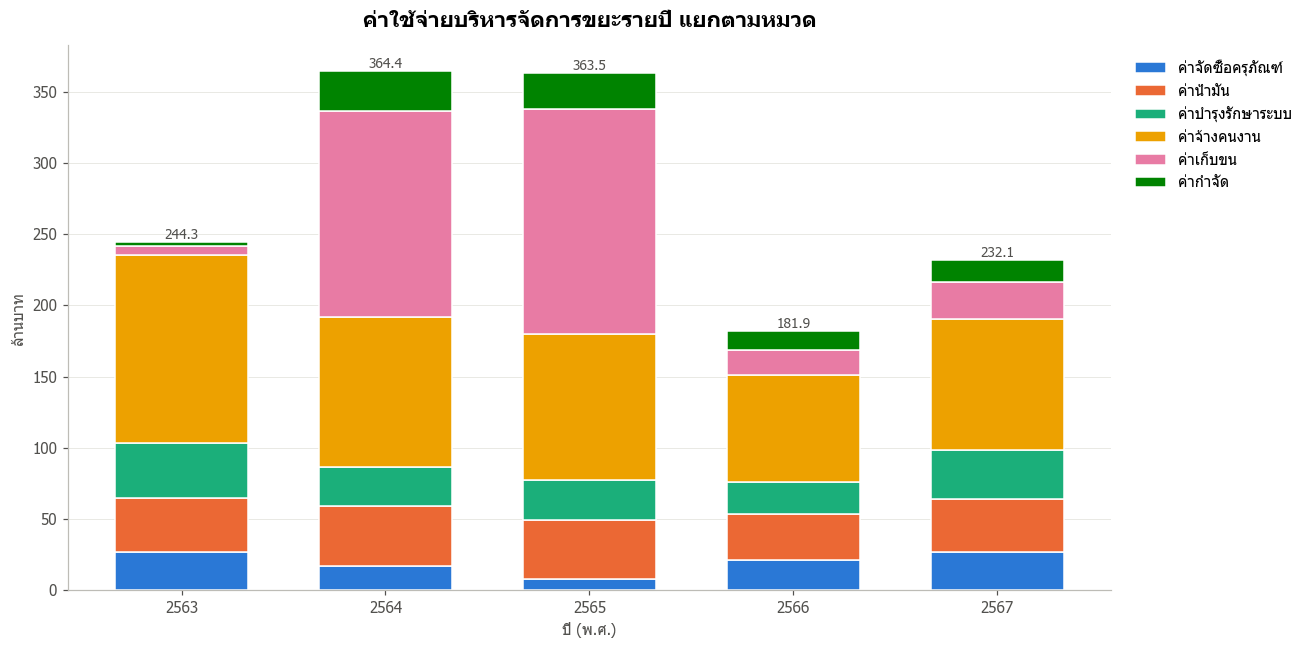

,ค่าจัดซื้อครุภัณฑ์,ค่าน้ำมัน,ค่าบำรุงรักษาระบบ,ค่าจ้างคนงาน,ค่าเก็บขน,ค่ากำจัด
ปี,,,,,,
2563,26.48,38.53,38.55,131.93,6.00,2.76
2564,16.91,42.09,27.64,105.40,144.22,28.10
2565,8.17,41.00,28.05,102.85,157.55,25.86
2566,20.87,32.79,22.28,74.87,17.72,13.39
2567,26.97,36.92,34.29,92.14,26.25,15.51


In [10]:
yearly_cost = viz.groupby('ปี')[cost_cols].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 6))
totals = stacked_bar(ax, yearly_cost, colors=[COST_COLOR[c] for c in cost_cols])
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.1f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.set_title('ค่าใช้จ่ายบริหารจัดการขยะรายปี แยกตามหมวด')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ล้านบาท')
plt.tight_layout(); plt.show()
yearly_cost.round(2)

### 2.2 Pie chart: cost structure over all 5 years
**How to read it:** each slice is that category's share of the total budget — the biggest slice is where cost reduction should be looked at first

### 2.2 แผนภูมิวงกลม: โครงสร้างค่าใช้จ่ายรวม 5 ปี
**วิธีอ่าน:** แต่ละชิ้นคือสัดส่วนของหมวดนั้นต่องบทั้งหมด — หมวดที่ชิ้นใหญ่ที่สุดคือจุดที่ควรหาทางลดต้นทุนก่อน

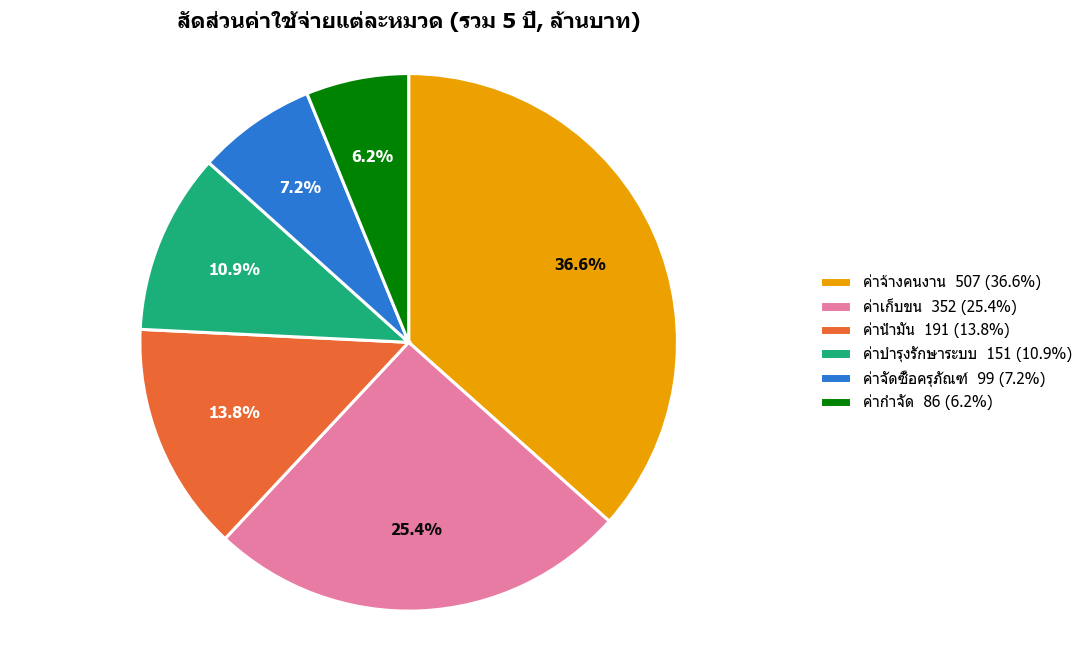

In [11]:
share = viz[cost_cols].sum().sort_values(ascending=False) / 1e6
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, share.values, share.index, colors=[COST_COLOR[c] for c in share.index],
          title='สัดส่วนค่าใช้จ่ายแต่ละหมวด (รวม 5 ปี, ล้านบาท)')
plt.tight_layout(); plt.show()

### 2.3 Heatmap: expenditure by district × category (million baht, 5 years combined)
**How to read it:** rows = districts, columns = categories, darker = more spending. It answers "what does each district spend its money on" — e.g. some districts hire private contractors for collection (high collection cost) instead of employing their own workers

### 2.3 Heatmap: ค่าใช้จ่ายแยกตามอำเภอ × หมวด (ล้านบาท, รวม 5 ปี)
**วิธีอ่าน:** แถว = อำเภอ, คอลัมน์ = หมวด, สีเข้ม = ใช้จ่ายมาก ช่วยตอบว่า "อำเภอแต่ละแห่งใช้เงินไปกับอะไร" เช่น บางอำเภอจ้างเอกชนเก็บขน (ค่าเก็บขนสูง) แทนการจ้างคนงานเอง

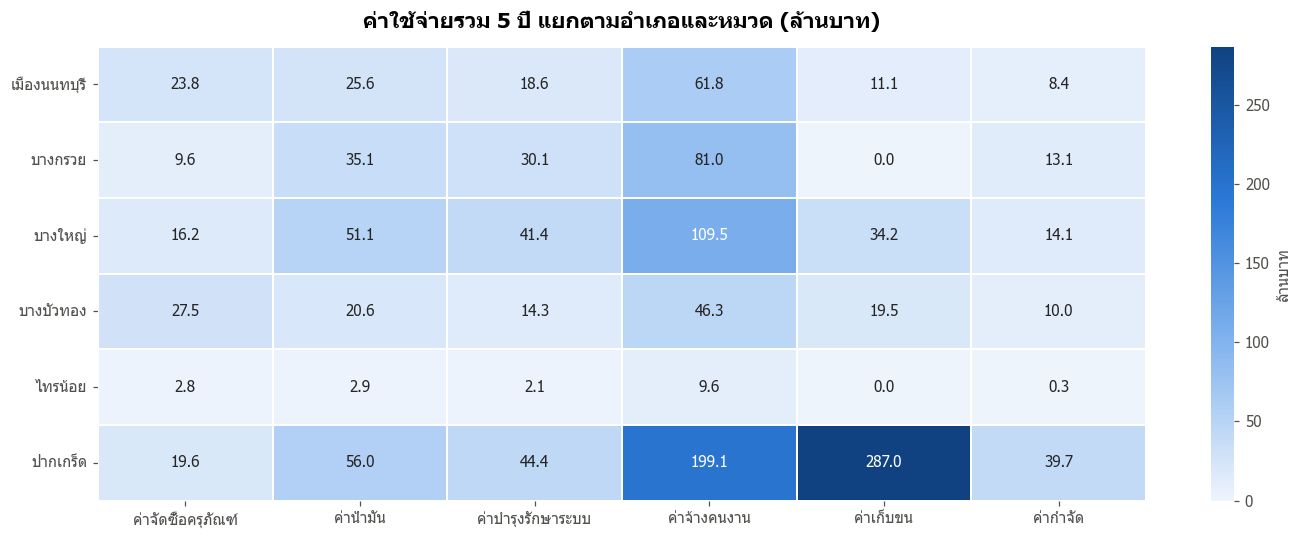

,ค่าจัดซื้อครุภัณฑ์,ค่าน้ำมัน,ค่าบำรุงรักษาระบบ,ค่าจ้างคนงาน,ค่าเก็บขน,ค่ากำจัด,รวม
อำเภอ,,,,,,,
ปากเกร็ด,19.57,56.03,44.38,199.07,286.98,39.66,645.69
บางใหญ่,16.16,51.06,41.42,109.47,34.22,14.14,266.48
บางกรวย,9.58,35.06,30.08,81.01,0.00,13.11,168.84
เมืองนนทบุรี,23.83,25.60,18.57,61.75,11.08,8.41,149.25
บางบัวทอง,27.47,20.63,14.25,46.31,19.46,10.03,138.15
ไทรน้อย,2.79,2.95,2.12,9.57,0.00,0.26,17.69


In [12]:
dist_cost = (viz.groupby('อำเภอ')[cost_cols].sum() / 1e6).reindex([d for d in DIST_ORDER if d in set(viz['อำเภอ'])])
dist_cost['รวม'] = dist_cost.sum(axis=1)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(dist_cost[cost_cols], annot=True, fmt=',.1f', cmap=SEQ_CMAP, linewidths=1, linecolor='white',
            cbar_kws={'label': 'ล้านบาท'}, ax=ax)
ax.set_title('ค่าใช้จ่ายรวม 5 ปี แยกตามอำเภอและหมวด (ล้านบาท)')
ax.set_xlabel(''); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()
dist_cost.round(2).sort_values('รวม', ascending=False)

### 2.4 Horizontal bar chart: top 10 local governments by total expenditure (5 years combined)
**How to read it:** the number in brackets is the % of the province's total budget — if a few local governments hold a large share, the budget is concentrated

### 2.4 กราฟแท่งแนวนอน: 10 อปท. ที่มีค่าใช้จ่ายรวมสูงสุด (รวม 5 ปี)
**วิธีอ่าน:** ตัวเลขในวงเล็บคือ % ของงบรวมทั้งจังหวัด — ถ้า อปท. ไม่กี่แห่งครองสัดส่วนสูง แปลว่างบประมาณกระจุกตัว

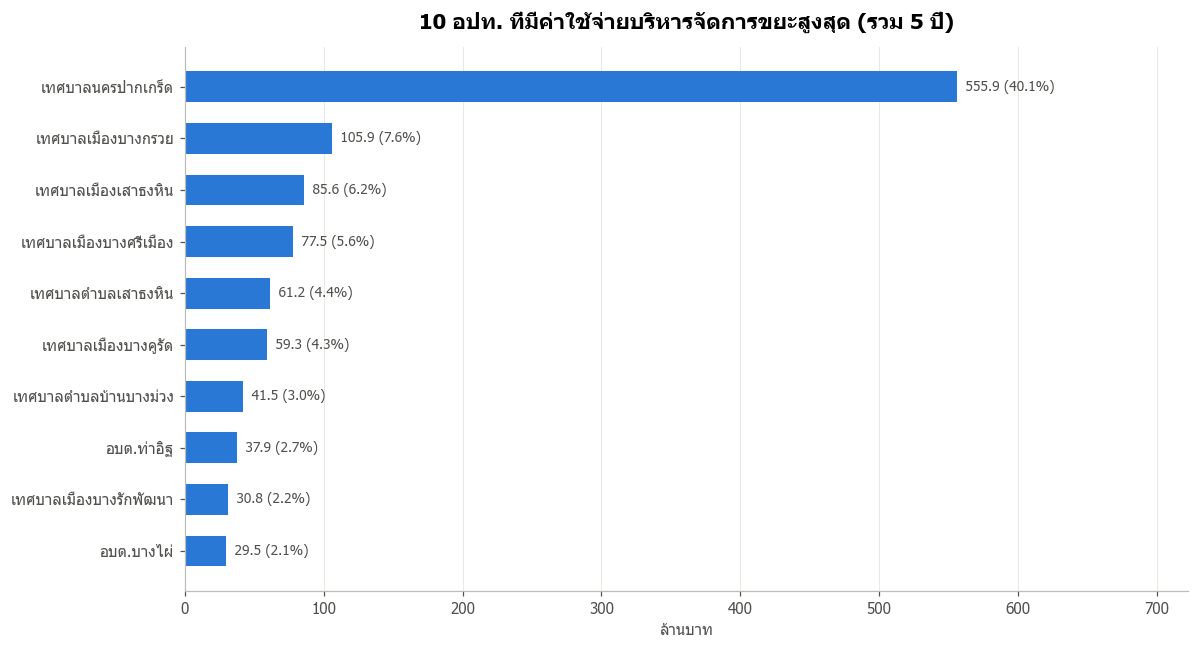

In [13]:
by_apt = viz.groupby('อปท')['ค่าใช้จ่ายรวม'].sum() / 1e6
top = by_apt.nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top.index, top.values, color=PALETTE[0], height=0.6)
for b, v in zip(bars, top.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f'  {v:,.1f} ({v / by_apt.sum() * 100:.1f}%)',
            va='center', fontsize=9, color=TEXT)
ax.set_xlim(0, top.max() * 1.3); ax.grid(axis='y', visible=False)
ax.set_title('10 อปท. ที่มีค่าใช้จ่ายบริหารจัดการขยะสูงสุด (รวม 5 ปี)'); ax.set_xlabel('ล้านบาท')
plt.tight_layout(); plt.show()

### 2.5 Line chart: waste management cost per tonne (baht/tonne) by district
**What it does:** sums municipal solid waste (`clean_community.csv`) by district and year, then calculates

`cost per tonne = total expenditure (baht) ÷ municipal solid waste (tonnes)`

**How to read it:** an efficiency measure that can be compared across districts (large districts naturally spend more, but the cost per tonne should be similar). An unusually high line = high unit cost, worth investigating further

> Caution: if some local governments did not report expenses (filled with 0), that district's cost per tonne will be lower than reality

### 2.5 กราฟเส้น: ต้นทุนการจัดการขยะต่อตัน (บาท/ตัน) รายอำเภอ
**ทำอะไร:** นำปริมาณขยะมูลฝอยชุมชน (`clean_community.csv`) มารวมรายอำเภอ-ปี แล้วคำนวณ

`ต้นทุนต่อตัน = ค่าใช้จ่ายรวม (บาท) ÷ ขยะมูลฝอยชุมชน (ตัน)`

**วิธีอ่าน:** เป็นตัวชี้วัดประสิทธิภาพที่เทียบข้ามอำเภอได้ (อำเภอใหญ่ใช้เงินมากเป็นปกติ แต่ต่อตันควรใกล้เคียงกัน) เส้นที่สูงผิดปกติ = ต้นทุนต่อหน่วยสูง ควรตรวจสอบเพิ่มเติม

> ข้อควรระวัง: ถ้า อปท. บางแห่งไม่รายงานค่าใช้จ่าย (ถูกเติมเป็น 0) ต้นทุนต่อตันของอำเภอนั้นจะต่ำกว่าความจริง

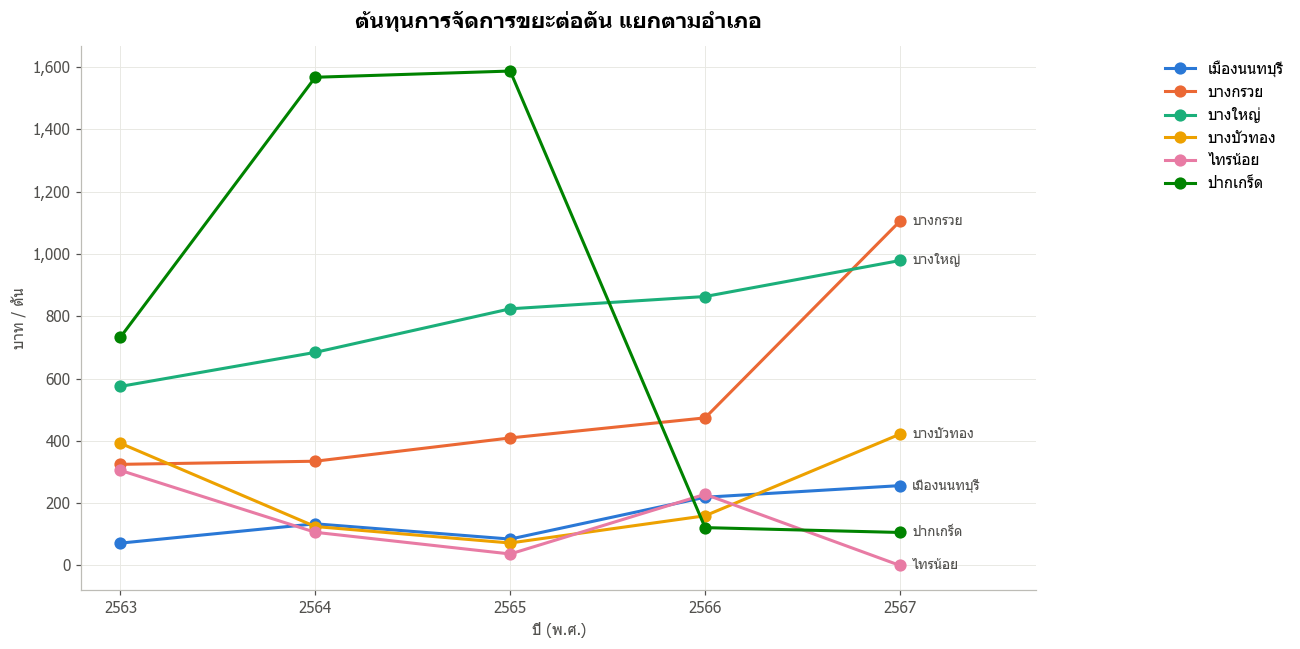

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด
ปี,,,,,,
2563,72.0,325.0,575.0,393.0,305.0,733.0
2564,134.0,335.0,684.0,125.0,107.0,1568.0
2565,85.0,410.0,824.0,72.0,37.0,1588.0
2566,219.0,474.0,864.0,160.0,228.0,122.0
2567,256.0,1106.0,979.0,422.0,0.0,106.0


In [14]:
comm = pd.read_csv('../data/clean/clean_community.csv')
waste_dy = comm.groupby(['ปี', 'อำเภอ'])['ขยะมูลฝอยชุมชน(ตัน)'].sum()
cost_dy = viz.groupby(['ปี', 'อำเภอ'])['ค่าใช้จ่ายรวม'].sum()
cpt = (cost_dy / waste_dy).unstack('อำเภอ')
cpt = cpt[[d for d in DIST_ORDER if d in cpt.columns]]

fig, ax = plt.subplots(figsize=(12, 6))
for d in cpt.columns:
    ax.plot(cpt.index, cpt[d], marker='o', markersize=7, linewidth=2, color=DIST_COLOR[d], label=d)
ax.set_xticks(cpt.index)
ax.set_xlim(cpt.index.min() - 0.2, cpt.index.max() + 0.7)
end_labels(ax, cpt.index[-1], [(d, cpt[d].iloc[-1]) for d in cpt.columns])
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(loc='upper left', bbox_to_anchor=(1.12, 1))
ax.set_title('ต้นทุนการจัดการขยะต่อตัน แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('บาท / ตัน')
plt.tight_layout(); plt.show()
cpt.round(0)

---
## Key Findings

1. **Total expenditure over 5 years is ~1,385 million baht** — highest in 2564–2565 (2021–2022, ~364 million baht/year), lowest in 2566 (2023, ~182 million baht)
2. **Worker wages are the largest category (36.6%)**, followed by collection & transport (25.4%) — waste collection is labor-intensive
3. **The spike in 2564–2565 comes from Pak Kret City Municipality alone** — collection & transport costs of ~140–147 million baht/year in only these two years (0 in other years), giving Pak Kret ~40% of the province's budget. Check whether these were real private contracts or a recording error (wrong category/unit)
4. **The province-wide average cost is ~280–560 baht/tonne.** Bang Yai and Bang Kruai have steadily rising costs per tonne (~1,000 baht/tonne in 2567), while Sai Noi and Pak Kret are very low in later years, probably because of incomplete expense data (filled with 0)

## สรุปข้อค้นพบ

1. **ค่าใช้จ่ายรวม 5 ปี ~1,385 ล้านบาท** — สูงสุดปี 2564–2565 (~364 ล้านบาท/ปี) ต่ำสุดปี 2566 (~182 ล้านบาท)
2. **ค่าจ้างคนงานเป็นหมวดใหญ่ที่สุด (36.6%)** ตามด้วยค่าเก็บขน (25.4%) — งานเก็บขยะใช้แรงงานมาก
3. **ยอดที่พุ่งในปี 2564–2565 มาจากเทศบาลนครปากเกร็ดแห่งเดียว** — ค่าเก็บขน ~140–147 ล้านบาท/ปี เฉพาะสองปีนี้ (ปีอื่นเป็น 0) ทำให้ปากเกร็ดครองงบ ~40% ของทั้งจังหวัด ควรตรวจว่าเป็นสัญญาจ้างเอกชนจริง หรือเป็นการบันทึกผิดหมวด/ผิดหน่วย
4. **ต้นทุนเฉลี่ยทั้งจังหวัดอยู่ที่ ~280–560 บาท/ตัน** อำเภอบางใหญ่และบางกรวยมีต้นทุนต่อตันสูงขึ้นต่อเนื่อง (~1,000 บาท/ตันในปี 2567) ขณะที่ไทรน้อยและปากเกร็ดในปีหลังต่ำมาก ซึ่งน่าจะมาจากข้อมูลค่าใช้จ่ายที่ไม่ครบ (เติม 0)